# ASTRA-Net | 3D Airway Segmentation Demo  
**Standalone Version**

Only a **3D chest `CT` volume in HU** is needed as the inference input  
The notebook imports project code exclusively from `astra_infer`  

**Requirements**

- A 3D chest `CT` in HU from the original dataset provider  
- The selected pretrained checkpoint from [ASTRA-Net Releases](https://github.com/guhong3648/ASTRA-Net/releases)  
- The local `./astra-airway/` module and its Python dependencies  

Run this notebook from `ASTRA-Net-main/src/` without `pip install`  
For the pip-based workflow, see `Demo_inference_pip_ver.ipynb`  

**Select a GPU in the first code cell**  
Restart the kernel after changing `GPU_NUM`

In [1]:
GPU_NUM = 0
GPU_NUM = str(GPU_NUM)

import os
import subprocess
import time
t0 = time.perf_counter()
os.environ['CUDA_DEVICE_ORDER'] = 'PCI_BUS_ID'
os.environ['CUDA_VISIBLE_DEVICES'] = GPU_NUM

gpu_info = subprocess.run(['nvidia-smi', '--query-gpu=index,name', '--format=csv,noheader'], capture_output=True, text=True)
gpu_names = {index.strip(): name.strip() for index, name in (line.split(',', 1) for line in gpu_info.stdout.splitlines() if ',' in line)}
gpu_name = gpu_names.get(GPU_NUM, 'Unknown GPU')
print(f'[{time.perf_counter()-t0:7.2f}s] GPU selected\n'
      f'            GPU {GPU_NUM}: {gpu_name} (visible as cuda:0)', flush=True)

# We used A5000 with 

[   0.09s] GPU selected
            GPU 0: NVIDIA RTX PRO 6000 Blackwell Server Edition (visible as cuda:0)


## 0. Download release assets

The selected checkpoint and our Enhanced annotations are downloaded automatically from [GitHub Releases](https://github.com/guhong3648/ASTRA-Net/releases) in Section 2  
Checkpoints are saved under `./astra-airway/model/`,  
and Enhanced annotations under `../data/raw/ATM26_Enhanced/`  

The example below uses **ATM_615** from ATM26 Track 1, but you can run the demo on **any 3D chest `CT` in HU**  
Download original `CT` images and annotations from the [ATM26](https://atm26.grand-challenge.org/registration/) official websites  
Note: **`Shanghai_184` in ATM26 Enhanced is the same CT case as `ATM_615` in ATM**  
Place the files in the directories shown below

```text
ASTRA-Net/
├── src/
│   ├── Demo_inference_standalone_ver.ipynb
│   └── astra-airway/
│       ├── astra_infer/
│       └── model/
│           └── ASTRA-Net_Phase2_Final.pt    # Automatically downloaded
├── data/
│   └── raw/
│       ├── ATM22_TrainBatch1/
│       │   └── TrainBatch1_CaseInfo.csv             # Case list for Preprocessing
│       ├── ATM22_TrainBatch2/
│       │   └── TrainBatch2_CaseInfo.csv             # Case list for Preprocessing
│       ├── ATM26_Track1/
│       │   ├── TrainBatch_CaseInfo.csv              # Case list for Preprocessing
│       │   ├── imagesTr/
│       │   │   └── ATM_615_0000.mha
│       │   └── labelsTr/
│       │       └── ATM_615.mha                      # Optional comparison
│       └── ATM26_Enhanced/
│           └── Shanghai_184_z_data.nii.gz-label.nrrd   # Same case as ATM_615
└── res/
    └── Demo_Output/
```

## 1. Import the local standalone package

Import `astra_infer` from `./astra-airway/` without installing the package  
Run this notebook from `ASTRA-Net-main/src/`  
Third-party dependencies must already be installed in the Jupyter environment

In [2]:
import sys
from pathlib import Path

PACKAGE_DIR = Path('./astra-airway').resolve()
sys.path.insert(0, str(PACKAGE_DIR))
print(f'Local package: {PACKAGE_DIR}')

Local package: /nas/Guhong/Airway/src/src/astra-airway


## 2. Configure model and file paths

Relative paths are resolved from the **current Jupyter working directory** (`ASTRA-Net-main/src/`)  
The default example uses **`ATM_615`** from ATM26 Track 1

In [3]:
t0 = time.perf_counter()
import numpy as np
import SimpleITK as sitk
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

MODEL_NAME = 'ASTRA-Net_Phase2'  # UNet, FANN, UDADS-Net, WingsNet, ASTRA-Net_Phase1, ASTRA-Net_Phase2
MODEL_DIR = Path('astra-airway/model')
CT_PATH = Path('../data/raw/ATM26_Track1/imagesTr/ATM_615_0000.mha')
GT_PATH = Path('../data/raw/ATM26_Track1/labelsTr/ATM_615.mha')
ENHANCED_DIR = Path('../data/raw/ATM26_Enhanced')
OUTPUT_DIR = Path('../res/Demo_Output')/MODEL_NAME

THRESHOLD = 0.20
OVERLAP = 32
BATCH_SIZE = 32
INFERENCE_EDGE = 65
FLIP_RAW_CT_Z = True  # ATM26 raw CT -> head-up training orientation; False if already aligned
DEVICE = 'cuda:0'
LUNG_WINDOW_CENTER = -600
LUNG_WINDOW_WIDTH = 1200
AW_CMAP = ListedColormap(['#00FF66'])

print(f'[{time.perf_counter()-t0:7.2f}s] Configuration\n'
      f'            Model      : {MODEL_NAME}\n'
      f'            Checkpoint : {MODEL_DIR/f"{MODEL_NAME}_Final.pt"}\n'
      f'            CT         : {CT_PATH}\n'
      f'            Output     : {OUTPUT_DIR}', flush=True)

[   0.40s] Configuration
            Model      : ASTRA-Net_Phase2
            Checkpoint : astra-airway/model/ASTRA-Net_Phase2_Final.pt
            CT         : ../data/raw/ATM26_Track1/imagesTr/ATM_615_0000.mha
            Output     : ../res/Demo_Output/ASTRA-Net_Phase2


In [4]:
from astra_infer.release_assets import ensure_checkpoint, download_enhanced_labels

download_force = True  # True: re-download and overwrite existing release assets

t0 = time.perf_counter()
checkpoint_path = ensure_checkpoint(MODEL_DIR/f'{MODEL_NAME}_Final.pt', MODEL_NAME, force=download_force)
enhanced_path = download_enhanced_labels('../data', force=download_force)
print(f'[{time.perf_counter()-t0:7.2f}s] Release assets ready\n'
      f'            Checkpoint : {checkpoint_path}\n'
      f'            Enhanced GT: {enhanced_path}', flush=True)

Download ASTRA-Net_Phase2_Final.pt: 100%|██████████| 23.6M/23.6M [00:01<00:00, 22.9MB/s]
Download ATM26_Enhanced_Labels.zip: 100%|██████████| 4.60M/4.60M [00:00<00:00, 17.4MB/s]


ATM26 Enhanced labels: 20 files -> ../data/raw/ATM26_Enhanced
[   6.14s] Release assets ready
            Checkpoint : astra-airway/model/ASTRA-Net_Phase2_Final.pt
            Enhanced GT: ../data/raw/ATM26_Enhanced


## 3. Load CT

SimpleITK preserves the original image geometry  
The input NumPy volume has shape `(Z, Y, X)` and intensities in **HU**

In [5]:
t0 = time.perf_counter()
ct_image = sitk.ReadImage(str(CT_PATH))
CT = sitk.GetArrayFromImage(ct_image).astype(np.float32)  # (Z, Y, X), HU
spacing_x, spacing_y, spacing_z = ct_image.GetSpacing()
print(f'[{time.perf_counter()-t0:7.2f}s] CT loaded\n'
      f'            Shape   : {CT.shape}\n'
      f'            HU      : [{CT.min():.0f}, {CT.max():.0f}]\n'
      f'            Spacing : {ct_image.GetSpacing()}', flush=True)

[  25.46s] CT loaded
            Shape   : (590, 512, 512)
            HU      : [-1024, 1696]
            Spacing : (0.8203125, 0.8203125, 0.5)


## 4. Run airway segmentation

`AWInferer` handles preprocessing, sliding-window inference, and postprocessing  
ASTRA-Net uses `LM` [LungMask (R231)](https://github.com/JoHof/lungmask), vessel context (`CV`), and positional encoding to predict the airway (`AW`)  
The reference models use `CT` directly and predict `AW`  
All returned masks are binary `uint8` arrays aligned with the input `CT`

**CT orientation:** This demo reverses the Z axis of raw ATM26 CT before inference (`FLIP_RAW_CT_Z=True`),  
then restores all masks to the original CT orientation for visualization and saving.  
Set `FLIP_RAW_CT_Z=False` if the CT is already in the head-up training orientation.  
`AWInferer` itself uses `align=False` and expects correctly oriented CT.

In [6]:
from astra_infer import AWInferer

t0 = time.perf_counter()
inferer = AWInferer(model_name=MODEL_NAME, model_dir=MODEL_DIR, threshold=THRESHOLD, overlap=OVERLAP, batch_size=BATCH_SIZE, inference_edge=INFERENCE_EDGE, device=DEVICE, align=False, verbose=True)
CT_aligned = np.ascontiguousarray(CT[::-1] if FLIP_RAW_CT_Z else CT)
output = inferer(CT_aligned)
if FLIP_RAW_CT_Z: output = {name:np.ascontiguousarray(mask[::-1]) for name, mask in output.items()}  # Restore raw CT orientation
AW = output['AW']
LM = output.get('LM')
CV = output.get('CV')
print(f'[{time.perf_counter()-t0:7.2f}s] Inference summary', flush=True)
for name, mask in output.items():
    print(f'            {name:<3} : {int(mask.sum()):>12,} voxels ({mask.dtype})', flush=True)

[   0.00s] [AWInferer] Model configuration
                      model=ASTRA-Net_Phase2 | device=cuda:0
                      patch=64 | overlap=32 | stride=32
                      edge=65 | batch=32 done
[   2.39s] [AWInferer] ASTRA-Net_Phase2 checkpoint loading | astra-airway/model/ASTRA-Net_Phase2_Final.pt done
Downloading: "https://github.com/JoHof/lungmask/releases/download/v0.0/unet_r231-d5d2fc3d.pth" to /root/.cache/torch/hub/checkpoints/unet_r231-d5d2fc3d.pth


100%|██████████| 119M/119M [00:04<00:00, 30.2MB/s] 


[   5.35s] [AWInferer] LungMask R231 loading done
[   0.00s] [AWInferer] [0/4] CT input | shape=(590, 512, 512) | Z flip=False done


 92%|█████████▏| 34/36.875 [00:01<00:00, 27.18it/s]/opt/conda/lib/python3.10/site-packages/tqdm/std.py:524: TqdmWarning: clamping frac to range [0, 1]
  full_bar = Bar(frac,
100%|██████████| 37/36.875 [00:01<00:00, 22.50it/s]

lungmask 2026-11-11 18:13:22 Postprocessing



100%|██████████| 5/5 [00:00<00:00, 92.56it/s]


[  30.10s] [AWInferer] [1/4] LungMask inference | voxels=16,946,449 done


[  26.57s] [AWInferer] [2/4] CV and positional encoding | LM bbox=(3:589, 172:404, 105:436) done


[AWInferer] ASTRA-Net_Phase2: 100%|██████████| 127/127 [00:41<00:00,  3.06batch/s]


[  47.79s] [AWInferer] [3/4] ASTRA-Net_Phase2 sliding-window inference done
[  34.95s] [AWInferer] [4/4] AW postprocessing | threshold=0.2 | edge=65 | voxels=219,864 done
[   0.00s] [AWInferer] Output ready | channels=['LM', 'CV', 'AW'] | Z flip restored=False | dtype=uint8 done
[ 139.43s] [AWInferer] CT-to-AW pipeline | shape=(590, 512, 512) done
[ 158.53s] Inference summary
            LM  :   16,946,449 voxels (uint8)
            CV  :      445,805 voxels (uint8)
            AW  :      219,864 voxels (uint8)


## 5. View three principal planes

Show **axial, coronal, and sagittal** projections with the predicted `AW` in green  
The `CT` is displayed using a lung window (center −600 HU, width 1200 HU)

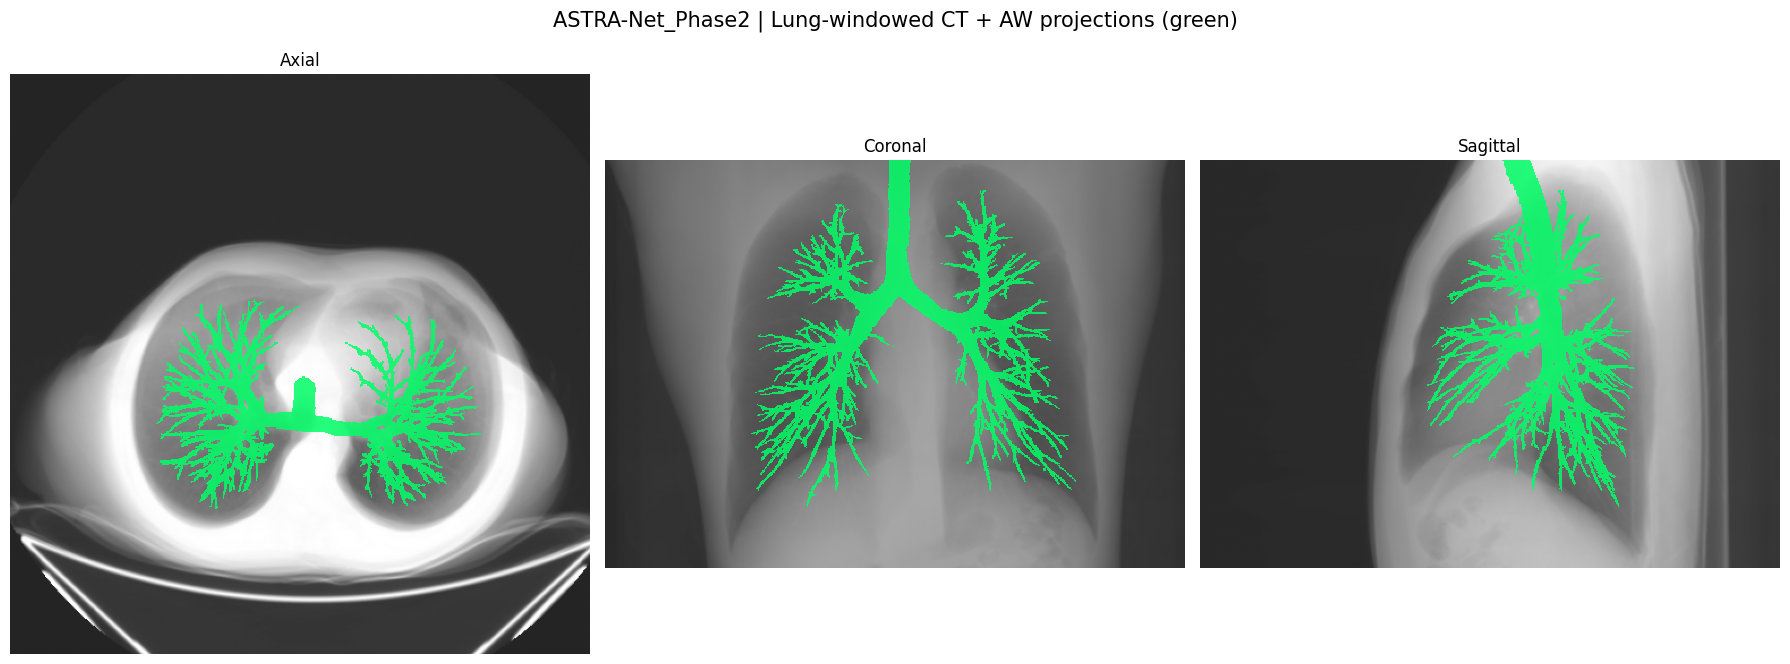

[   4.28s] Three principal plane projections


In [7]:
def plot_ct_aw(ax, ct_plane, aw_plane, aspect=1):
    vmin = LUNG_WINDOW_CENTER-LUNG_WINDOW_WIDTH/2
    vmax = LUNG_WINDOW_CENTER+LUNG_WINDOW_WIDTH/2
    ax.imshow(ct_plane, cmap='gray', vmin=vmin, vmax=vmax, aspect=aspect, origin='upper')
    ax.imshow(np.ma.masked_where(aw_plane == 0, aw_plane), cmap=AW_CMAP, vmin=0, vmax=1, alpha=0.85, aspect=aspect, interpolation='nearest', origin='upper')
    ax.axis('off')

views = [
    ('Axial', 0, spacing_y/spacing_x),
    ('Coronal', 1, spacing_z/spacing_x),
    ('Sagittal', 2, spacing_z/spacing_y),
]

t0 = time.perf_counter()
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, (title, axis, aspect) in zip(axes, views):
    vmin = LUNG_WINDOW_CENTER-LUNG_WINDOW_WIDTH/2
    vmax = LUNG_WINDOW_CENTER+LUNG_WINDOW_WIDTH/2
    ct_proj = np.clip(CT, vmin, vmax).mean(axis=axis)
    aw_proj = AW.max(axis=axis)
    if axis in (1, 2):
        ct_proj = np.flipud(ct_proj)
        aw_proj = np.flipud(aw_proj)
    plot_ct_aw(ax, ct_proj, aw_proj, aspect=aspect)
    ax.set_title(title)
fig.suptitle(f'{MODEL_NAME} | Lung-windowed CT + AW projections (green)', fontsize=15)
plt.tight_layout()
plt.show()
print(f'[{time.perf_counter()-t0:7.2f}s] Three principal plane projections', flush=True)

## 6. View 16 axial slices

View **16 evenly spaced axial slices** with a consistent crop and green `AW` overlay  
Adjust the lung window in the first two lines of the cell below

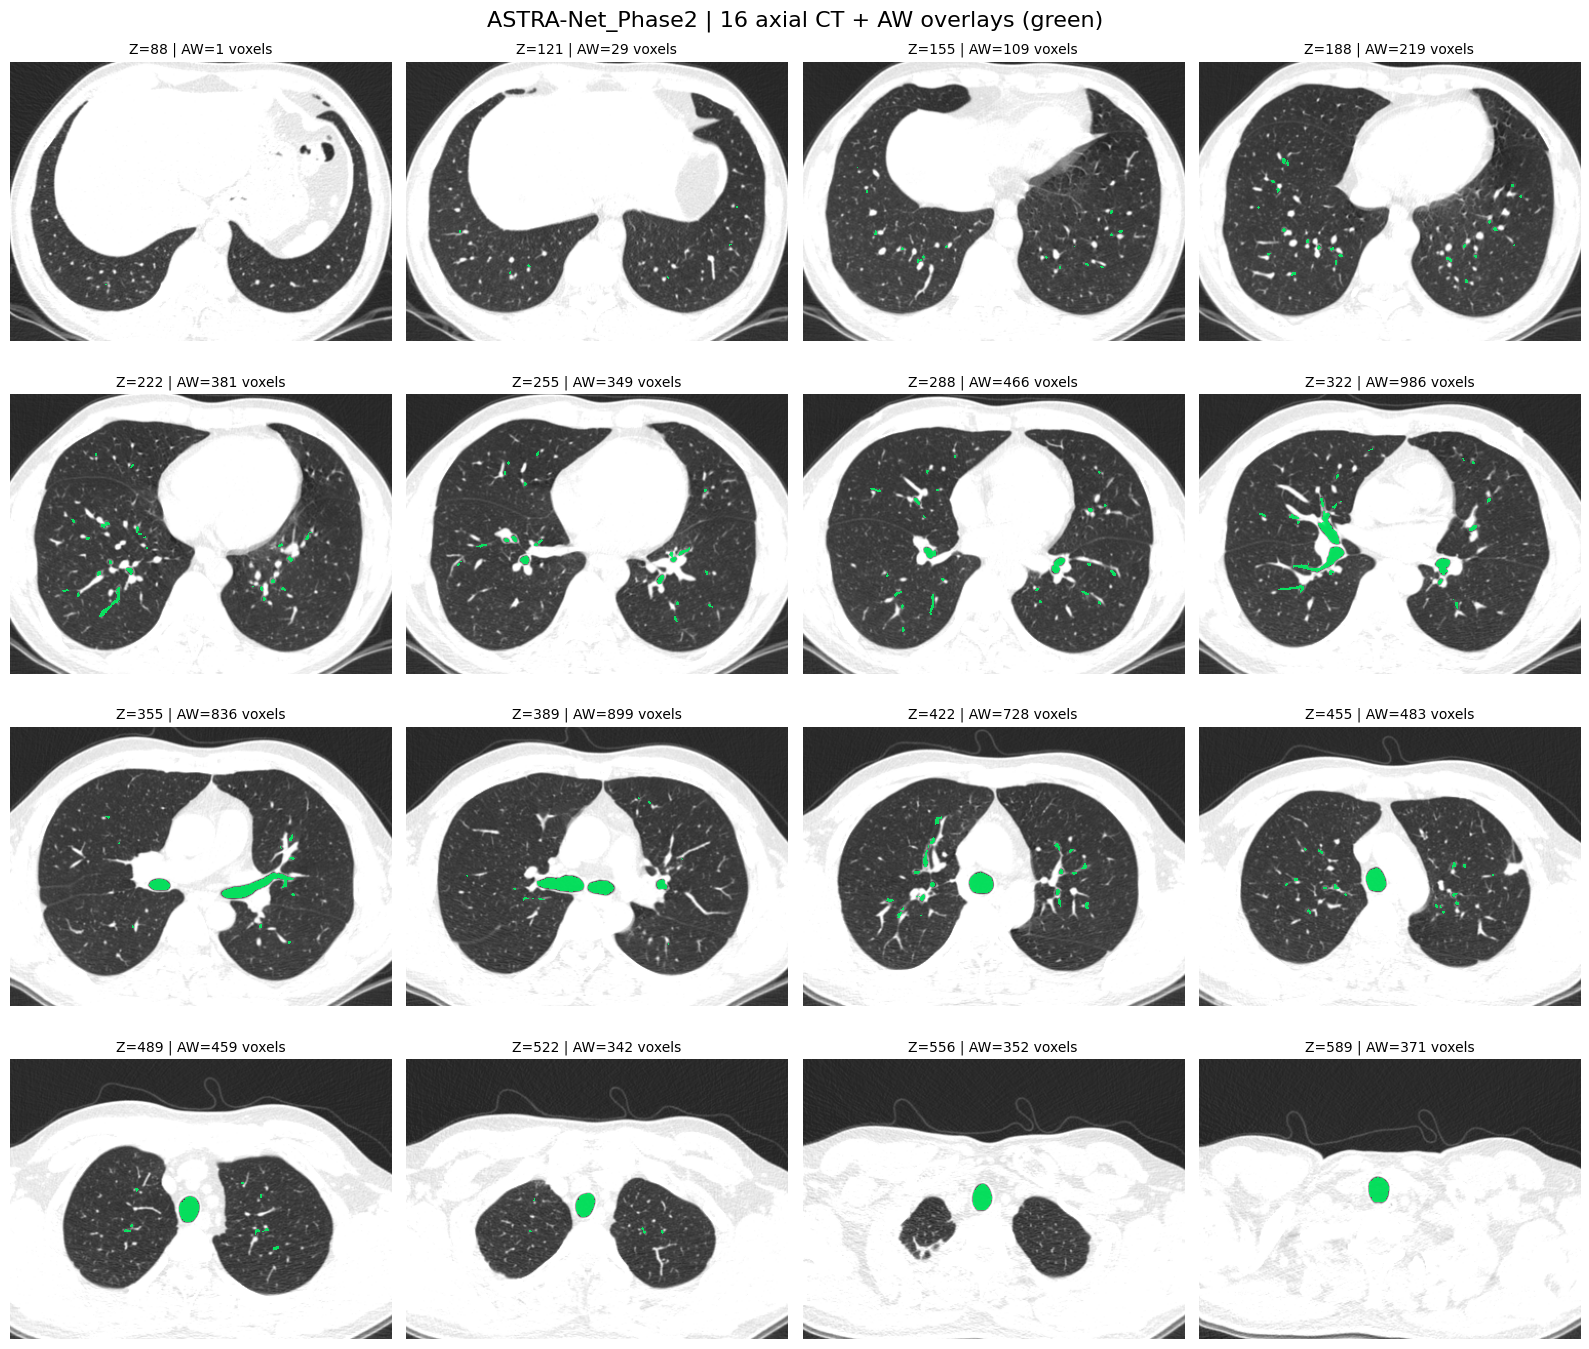

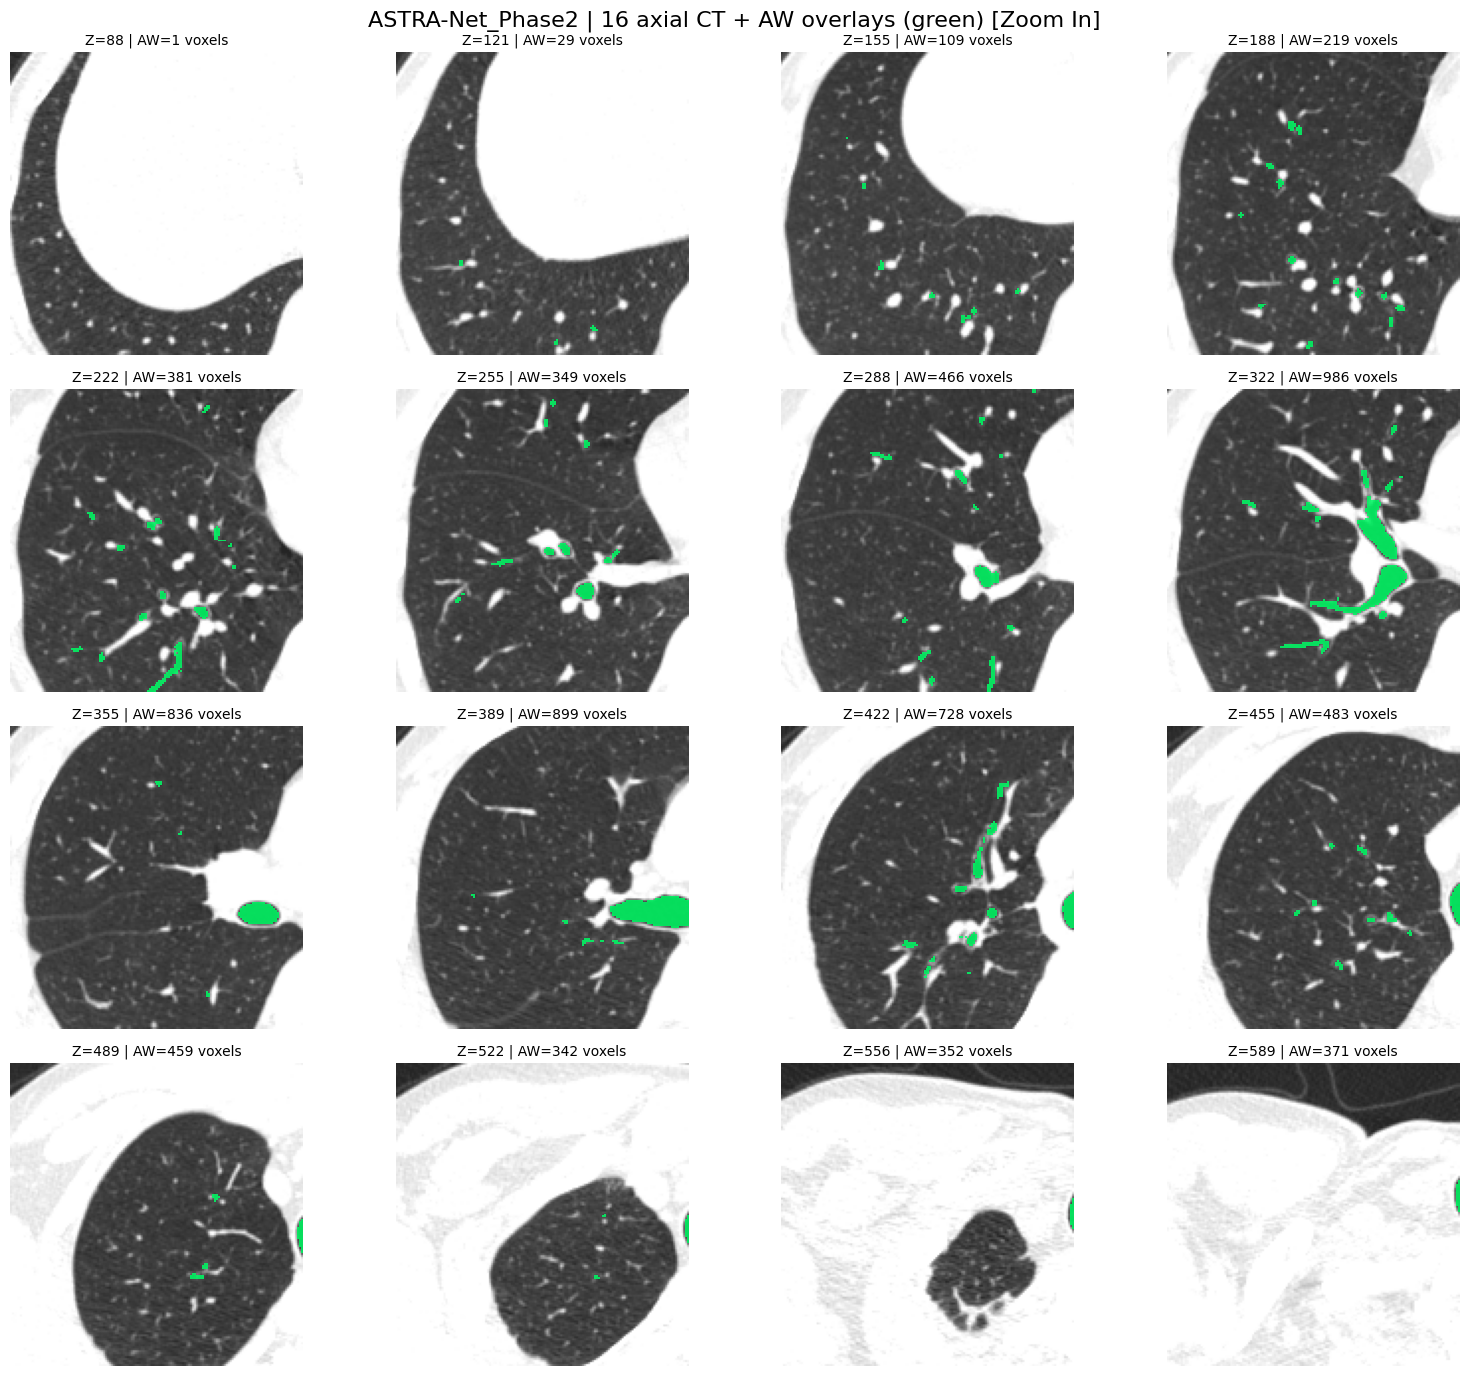

In [8]:
LUNG_WINDOW_CENTER = -600
LUNG_WINDOW_WIDTH = 1200

aw_z = np.where(np.any(AW > 0, axis=(1, 2)))[0]
if len(aw_z) == 0: raise ValueError('The predicted AW mask is empty; there are no axial slices to visualize.')

slice_indices = np.rint(np.linspace(aw_z[0], aw_z[-1], 16)).astype(int)
lung_xy = np.any((LM > 0) | (AW > 0), axis=0) if LM is not None else np.any(AW > 0, axis=0)
ys, xs = np.where(lung_xy)
margin = 20
y0, y1 = max(0, ys.min()-margin), min(CT.shape[1], ys.max()+margin+1)
x0, x1 = max(0, xs.min()-margin), min(CT.shape[2], xs.max()+margin+1)

fig, axes = plt.subplots(4, 4, figsize=(16, 14))
for ax, z in zip(axes.flat, slice_indices):
    plot_ct_aw(ax, CT[z, y0:y1, x0:x1], AW[z, y0:y1, x0:x1], aspect=spacing_y/spacing_x)
    ax.set_title(f'Z={z} | AW={int(AW[z].sum()):,} voxels', fontsize=10)
fig.suptitle(f'{MODEL_NAME} | 16 axial CT + AW overlays (green)', fontsize=16)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(4, 4, figsize=(16, 14))
x0_ = x0+20
x1_ = int(x1/1.8)
y0_ = y0+60
y1_ = y1-60
for ax, z in zip(axes.flat, slice_indices):
    plot_ct_aw(ax, CT[z, y0_:y1_, x0_:x1_], AW[z, y0_:y1_, x0_:x1_], aspect=spacing_y/spacing_x)
    ax.set_title(f'Z={z} | AW={int(AW[z].sum()):,} voxels', fontsize=10)
fig.suptitle(f'{MODEL_NAME} | 16 axial CT + AW overlays (green) [Zoom In]', fontsize=16)
plt.tight_layout()
plt.show()

## 7. Compare with ground truth (optional)

Compare **GT, Enhanced, and Pred** at a selected axial slice  
For this demo, **ATM_615** in ATM Track 1 is the same case as **Shanghai_184**  
The Enhanced label uses the ATM22 raw ROI (832 slices), so it is cropped to **Z=147:737** to match the ATM26  raw CT (590 slices)
The crop was verified by directly comparing the original ATM22/ATM26 CT volumes (**MAE = 0 HU**)  
The Enhanced label is automatically downloaded in Section 2; the original GT is optional  
Set `z` manually in the following cell to explore another slice  

Quantitative metrics are omitted due to their computational cost  
For quantitative evaluation, refer to the README and the `evaluation` scripts 

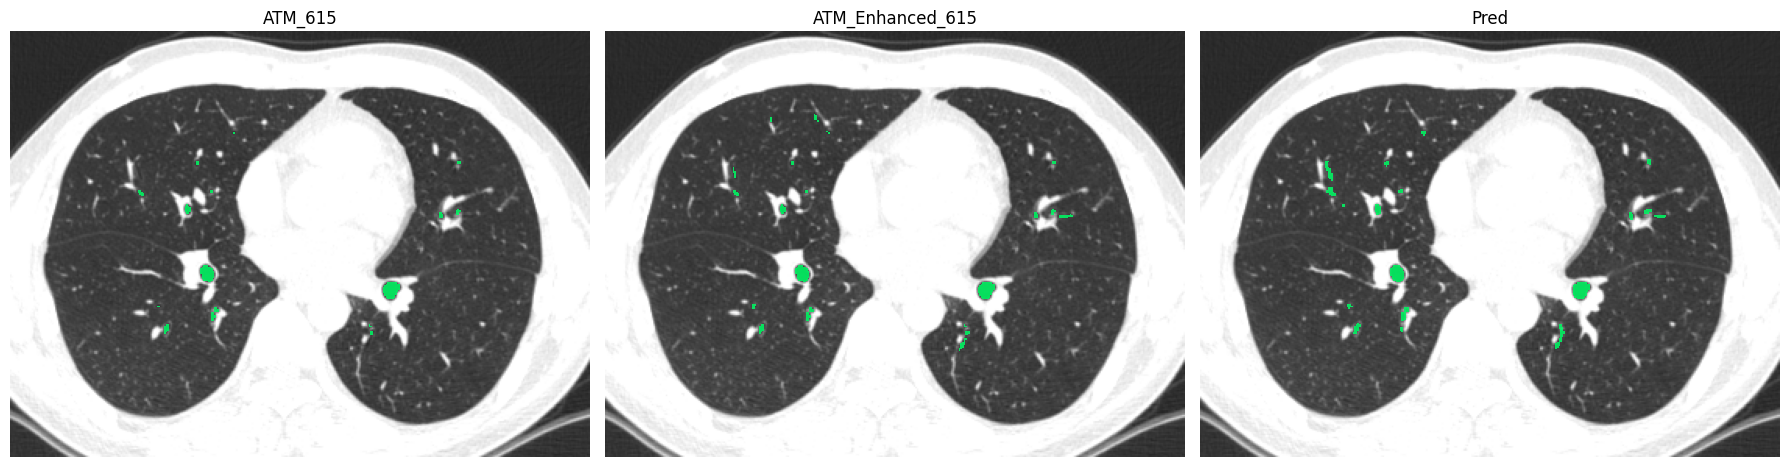

[   1.90s] GT/Enhanced/Pred comparison at Z=300


In [9]:
z = int(slice_indices[len(slice_indices)//2])
z = 300  # Manual exploration

t0 = time.perf_counter()
if GT_PATH.is_file():
    gt_image = sitk.ReadImage(str(GT_PATH))
    GT = (sitk.GetArrayFromImage(gt_image) > 0).astype(np.uint8)
    enhanced_image = sitk.ReadImage(str(ENHANCED_DIR/'Shanghai_184_z_data.nii.gz-label.nrrd'))
    Enhanced = (sitk.GetArrayFromImage(enhanced_image)[147:737] > 0).astype(np.uint8)  # ATM_615 = Shanghai_184, raw ATM22 -> ATM26 ROI

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    plot_ct_aw(axes[0], CT[z, y0:y1, x0:x1], GT[z, y0:y1, x0:x1], aspect=spacing_y/spacing_x)
    plot_ct_aw(axes[1], CT[z, y0:y1, x0:x1], Enhanced[z, y0:y1, x0:x1], aspect=spacing_y/spacing_x)
    plot_ct_aw(axes[2], CT[z, y0:y1, x0:x1], AW[z, y0:y1, x0:x1], aspect=spacing_y/spacing_x)
    axes[0].set_title('ATM_615')
    axes[1].set_title('ATM_Enhanced_615')
    axes[2].set_title('Pred')
    plt.tight_layout()
    plt.show()
    print(f'[{time.perf_counter()-t0:7.2f}s] GT/Enhanced/Pred comparison at Z={z}', flush=True)
else:
    print('GT comparison skipped (no reference file)', flush=True)


## 8. Save segmentation masks

In [10]:
t0 = time.perf_counter()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for name, mask in output.items():
    image = sitk.GetImageFromArray(mask)
    image.CopyInformation(ct_image)
    sitk.WriteImage(image, str(OUTPUT_DIR/f'{name}.nii.gz'))
print(f'[{time.perf_counter()-t0:7.2f}s] Saved NIfTI masks\n'
      f'            Directory : {OUTPUT_DIR}\n'
      f'            Files     : {", ".join(f"{name}.nii.gz" for name in output)}', flush=True)

[   1.07s] Saved NIfTI masks
            Directory : ../res/Demo_Output/ASTRA-Net_Phase2
            Files     : LM.nii.gz, CV.nii.gz, AW.nii.gz


## 9. Shut down the Jupyter kernel (optional)

Run the cell below **only when you are finished**  
It forcefully terminates the current Jupyter kernel process  
Any variables stored in memory will be lost, and the notebook will disconnect

In [11]:
# Optional: force-stop this notebook's kernel.
# import os
# os.system(f'kill -9 {os.getpid()}')